# 10 — Do we need separate models?

This notebook tests whether economically motivated segmentation improves on the frozen global benchmark. It does **not** assume that the visibly weak segments in Notebook 09 require separate models.

The comparison has three architecture classes:

1. **Pooled interactions**: one model, but selected slopes may differ by size, liquidity, or auction-intensity tertile.
2. **Hard splits**: independent models by size, liquidity, auction intensity, or a coarse size×liquidity grid.
3. **Targeted hybrids**: retain the global model for ordinary observations and use a specialist only for event days or stocks with fewer than 20 prior auctions.

All assignments use only lagged/cross-sectional features already marked daily-safe. The same rolling five-year history, median-20 residual target, annual out-of-time folds, and 2022–2024 development / 2025 confirmation convention used to freeze the global benchmark are retained.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 180)
pd.set_option("display.max_rows", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (13, 7), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")
sys.path.insert(0, str(PROJECT_ROOT))

from notebooks.modeling_utils import (
    fit_preprocessor, apply_preprocessor, fit_ridge, predict_ridge, forecast_metrics
)

PANEL = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "enriched_daily_panel.parquet"
CATALOG = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "approved_enriched_daily_features.csv"
PRIOR_OUT = PROJECT_ROOT / "outputs" / "eda" / "09_global_finalists"
PRIOR_PREDICTIONS = PRIOR_OUT / "predictions"
OUT = PROJECT_ROOT / "outputs" / "eda" / "10_segmentation_tests"
PREDICTIONS = OUT / "predictions"
OUT.mkdir(parents=True, exist_ok=True)
PREDICTIONS.mkdir(parents=True, exist_ok=True)

with open(PRIOR_OUT / "frozen_global_benchmark.json") as handle:
    FROZEN = json.load(handle)
CHAMPION = FROZEN["champion"]
SECONDARY = "rolling5_residual_recent_full"
FEATURES = FROZEN["features"]

catalog = pd.read_csv(CATALOG)
all_approved_features = catalog["variable"].tolist()

BOOLEAN_FEATURES_ALL = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
    "lag1_dividend_flag", "lag1_distribution_flag", "lag1_price_adjustment_flag",
]
CATEGORICAL_FEATURES_ALL = ["month", "day_of_week", "ff12_code", "size_decile", "liquidity_decile"]
BOOLEAN_FEATURES = [f for f in FEATURES if f in BOOLEAN_FEATURES_ALL]
CATEGORICAL_FEATURES = [f for f in FEATURES if f in CATEGORICAL_FEATURES_ALL]
CONTINUOUS_FEATURES = [f for f in FEATURES if f not in BOOLEAN_FEATURES and f not in CATEGORICAL_FEATURES]

CONTEXT = [
    "date", "permno", "auction_volume", "log1p_auction_volume", "median20_auction_volume",
    "size_percentile", "liquidity_percentile", "auction_intensity_percentile",
    "prior_auction_observations", "quarterly_options_expiry", "monthly_options_expiry",
    "is_last_trading_day_month", "is_early_close",
]
QUERY_COLUMNS = list(dict.fromkeys(CONTEXT + FEATURES))
QUOTED_COLUMNS = ", ".join(f'"{c}"' for c in QUERY_COLUMNS)

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query, params=None):
    return con.execute(query, params or []).df()

print(f"Frozen reference: {CHAMPION} ({len(FEATURES)} source features)")
print(f"Secondary reference: {SECONDARY} (99 features, recent weights)")

Frozen reference: rolling5_residual_auction_calendar_liquidity (58 source features)
Secondary reference: rolling5_residual_recent_full (99 features, recent weights)


## Predeclared segments and candidates

Tertiles are based on lagged daily cross-sectional percentiles already present in the panel. The combined size×liquidity split is deliberately limited to a 2×2 grid. Event precedence is quarterly expiry, monthly expiry, month-end, early close, then regular.

Only a compact set of economically interpretable slopes is interacted. This makes the pooled alternatives flexible without turning them into opaque expansions of every dummy and missingness indicator.

In [2]:
TEST_YEARS = [2022, 2023, 2024, 2025]
DEVELOPMENT_YEARS = [2022, 2023, 2024]
CONFIRMATION_YEAR = 2025
LAMBDA_GRID = [1e-7, 1e-5, 1e-3, 1e-1]
TUNE_ROWS = 250_000
VALIDATION_ROWS = 120_000
REFIT_ROWS = 350_000
MIN_TRAINING_ROWS = 2_000
SEED = 20261012

INTERACTION_SOURCES = [
    "lag1_auction_volume", "avg5_auction_volume", "avg20_auction_volume",
    "median20_auction_volume", "std20_auction_volume", "auction_cv20",
    "auction_short_long_ratio", "lag1_auction_share", "avg20_auction_share",
    "lag1_auction_to_adv20", "prior_auction_observations", "avg20_daily_volume",
    "avg20_turnover", "lag1_quoted_spread",
]

MODEL_CANDIDATES = [
    "interaction_size", "interaction_liquidity", "interaction_intensity",
    "split_size", "split_liquidity", "split_intensity", "split_size_liquidity_2x2",
    "event_hybrid", "history_hybrid",
]

def tertile(values):
    x = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float)
    return np.where(~np.isfinite(x), "unknown", np.where(x < 1/3, "low", np.where(x < 2/3, "mid", "high")))

def half(values):
    x = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float)
    return np.where(~np.isfinite(x), "unknown", np.where(x < 0.5, "low", "high"))

def segment_labels(frame, dimension):
    if dimension == "size":
        return tertile(frame["size_percentile"])
    if dimension == "liquidity":
        return tertile(frame["liquidity_percentile"])
    if dimension == "intensity":
        return tertile(frame["auction_intensity_percentile"])
    if dimension == "size_liquidity_2x2":
        return np.char.add(np.char.add(half(frame["size_percentile"]).astype(str), "_size__"),
                           np.char.add(half(frame["liquidity_percentile"]).astype(str), "_liq"))
    if dimension == "event":
        q = frame["quarterly_options_expiry"].fillna(False).to_numpy(bool)
        m = frame["monthly_options_expiry"].fillna(False).to_numpy(bool)
        eom = frame["is_last_trading_day_month"].fillna(False).to_numpy(bool)
        early = frame["is_early_close"].fillna(False).to_numpy(bool)
        return np.where(q, "quarterly_expiry", np.where(m, "monthly_expiry",
            np.where(eom, "month_end", np.where(early, "early_close", "regular"))))
    if dimension == "history":
        n = pd.to_numeric(frame["prior_auction_observations"], errors="coerce").fillna(0).to_numpy()
        return np.where(n < 5, "cold_0_4", np.where(n < 20, "developing_5_19", "seasoned_20_plus"))
    raise ValueError(dimension)

candidate_design = pd.DataFrame([
    ("interaction_size", "pooled interaction", "size tertiles", "Residual target; selected slopes vary"),
    ("interaction_liquidity", "pooled interaction", "liquidity tertiles", "Residual target; selected slopes vary"),
    ("interaction_intensity", "pooled interaction", "auction-intensity tertiles", "Residual target; selected slopes vary"),
    ("split_size", "hard split", "size tertiles", "Independent residual models"),
    ("split_liquidity", "hard split", "liquidity tertiles", "Independent residual models"),
    ("split_intensity", "hard split", "auction-intensity tertiles", "Independent residual models"),
    ("split_size_liquidity_2x2", "hard split", "2x2 size×liquidity", "Independent residual models"),
    ("event_hybrid", "specialist hybrid", "calendar event regime", "Specialists for non-regular regimes; global fallback"),
    ("history_hybrid", "specialist hybrid", "fewer than 20 prior auctions", "Pooled log-level specialist; residual model otherwise"),
], columns=["candidate", "architecture", "segmentation", "estimation"])
candidate_design.to_csv(OUT / "candidate_design.csv", index=False)
display(candidate_design)

,candidate,architecture,segmentation,estimation
0,interaction_size,pooled interaction,size tertiles,Residual target; selected slopes vary
1,interaction_liquidity,pooled interaction,liquidity tertiles,Residual target; selected slopes vary
2,interaction_intensity,pooled interaction,auction-intensity tertiles,Residual target; selected slopes vary
3,split_size,hard split,size tertiles,Independent residual models
4,split_liquidity,hard split,liquidity tertiles,Independent residual models
5,split_intensity,hard split,auction-intensity tertiles,Independent residual models
6,split_size_liquidity_2x2,hard split,2x2 size×liquidity,Independent residual models
7,event_hybrid,specialist hybrid,calendar event regime,Specialists for non-regular regimes; global fa...
8,history_hybrid,specialist hybrid,fewer than 20 prior auctions,Pooled log-level specialist; residual model ot...


## Shared loading and model helpers

In [3]:
def load_period(start_date, end_date, sample_rows=None, seed=SEED, extra_where=""):
    sample_clause = f"USING SAMPLE {sample_rows} ROWS (reservoir, {seed})" if sample_rows else ""
    where = f"AND ({extra_where})" if extra_where else ""
    return sql(f"""
        SELECT * FROM (
            SELECT {QUOTED_COLUMNS}
            FROM read_parquet('{PANEL}')
            WHERE eligible_target AND date >= DATE '{start_date}' AND date < DATE '{end_date}' {where}
        ) {sample_clause}
    """)

def residual_target_and_base(train, score):
    fallback = float(np.median(train["auction_volume"]))
    train_base = train["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    score_base = score["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    target = train["log1p_auction_volume"].to_numpy(dtype=float) - np.log1p(train_base)
    return target, np.log1p(score_base)

def clip_log_predictions(train, values):
    lo, hi = np.quantile(train["log1p_auction_volume"].to_numpy(dtype=float), [0.001, 0.999])
    return np.clip(values, lo, hi)

def fit_global_residual(train, score, x_train, x_score, strength):
    target, score_base = residual_target_and_base(train, score)
    coef = fit_ridge(x_train, target, strength)
    return clip_log_predictions(train, predict_ridge(x_score, coef) + score_base)

def interaction_matrix(matrix, labels, prep, reference="mid"):
    sources = np.asarray(prep["output_sources"])
    slope_mask = np.isin(sources, INTERACTION_SOURCES)
    pieces = [matrix]
    levels = sorted(set(labels) - {reference})
    for level in levels:
        gate = (labels == level).astype(np.float32)[:, None]
        pieces.append(gate)
        pieces.append(matrix[:, slope_mask] * gate)
    return np.column_stack(pieces).astype(np.float32), levels, slope_mask

def apply_interaction_matrix(matrix, labels, slope_mask, levels):
    pieces = [matrix]
    for level in levels:
        gate = (labels == level).astype(np.float32)[:, None]
        pieces.append(gate)
        pieces.append(matrix[:, slope_mask] * gate)
    return np.column_stack(pieces).astype(np.float32)

def fit_interaction(train, score, x_train, x_score, prep, dimension, strength):
    train_labels = segment_labels(train, dimension)
    score_labels = segment_labels(score, dimension)
    xi_train, levels, slope_mask = interaction_matrix(x_train, train_labels, prep)
    xi_score = apply_interaction_matrix(x_score, score_labels, slope_mask, levels)
    target, score_base = residual_target_and_base(train, score)
    coef = fit_ridge(xi_train, target, strength)
    return clip_log_predictions(train, predict_ridge(xi_score, coef) + score_base)

def fit_hard_split(train, score, x_train, x_score, dimension, strength, counts=None):
    train_labels = segment_labels(train, dimension)
    score_labels = segment_labels(score, dimension)
    target, score_base = residual_target_and_base(train, score)
    prediction = np.full(len(score), np.nan)
    global_coef = fit_ridge(x_train, target, strength)
    for level in np.unique(score_labels):
        train_mask = train_labels == level
        score_mask = score_labels == level
        if counts is not None:
            counts.append({"dimension": dimension, "segment": level, "training_rows": int(train_mask.sum())})
        if train_mask.sum() >= MIN_TRAINING_ROWS:
            coef = fit_ridge(x_train[train_mask], target[train_mask], strength)
        else:
            coef = global_coef
        prediction[score_mask] = predict_ridge(x_score[score_mask], coef) + score_base[score_mask]
    return clip_log_predictions(train, prediction)

def fit_event_hybrid(train, score, x_train, x_score, strength, counts=None):
    train_labels = segment_labels(train, "event")
    score_labels = segment_labels(score, "event")
    target, score_base = residual_target_and_base(train, score)
    global_coef = fit_ridge(x_train, target, strength)
    prediction = predict_ridge(x_score, global_coef) + score_base
    for level in ["quarterly_expiry", "monthly_expiry", "month_end"]:
        train_mask, score_mask = train_labels == level, score_labels == level
        if counts is not None:
            counts.append({"dimension": "event", "segment": level, "training_rows": int(train_mask.sum())})
        if train_mask.sum() >= MIN_TRAINING_ROWS and score_mask.any():
            coef = fit_ridge(x_train[train_mask], target[train_mask], strength)
            prediction[score_mask] = predict_ridge(x_score[score_mask], coef) + score_base[score_mask]
    return clip_log_predictions(train, prediction)

def fit_history_hybrid(train, score, x_train, x_score, strength, rare_train=None, x_rare=None, counts=None):
    target, score_base = residual_target_and_base(train, score)
    global_coef = fit_ridge(x_train, target, strength)
    prediction = predict_ridge(x_score, global_coef) + score_base
    score_rare = pd.to_numeric(score["prior_auction_observations"], errors="coerce").fillna(0).to_numpy() < 20
    source = rare_train if rare_train is not None and len(rare_train) >= MIN_TRAINING_ROWS else train
    source_x = x_rare if rare_train is not None and len(rare_train) >= MIN_TRAINING_ROWS else x_train
    source_mask = pd.to_numeric(source["prior_auction_observations"], errors="coerce").fillna(0).to_numpy() < 20
    if counts is not None:
        counts.append({"dimension": "history", "segment": "prior_lt_20", "training_rows": int(source_mask.sum())})
    if source_mask.sum() >= MIN_TRAINING_ROWS and score_rare.any():
        # Direct log-level target avoids relying on an immature median-20 baseline.
        coef = fit_ridge(source_x[source_mask], source.loc[source_mask, "log1p_auction_volume"], strength)
        prediction[score_rare] = predict_ridge(x_score[score_rare], coef)
    return clip_log_predictions(train, prediction)

def score_candidate(name, train, score, x_train, x_score, prep, strength,
                    rare_train=None, x_rare=None, counts=None):
    if name.startswith("interaction_"):
        return fit_interaction(train, score, x_train, x_score, prep, name.replace("interaction_", ""), strength)
    if name.startswith("split_"):
        return fit_hard_split(train, score, x_train, x_score, name.replace("split_", ""), strength, counts)
    if name == "event_hybrid":
        return fit_event_hybrid(train, score, x_train, x_score, strength, counts)
    if name == "history_hybrid":
        return fit_history_hybrid(train, score, x_train, x_score, strength, rare_train, x_rare, counts)
    raise ValueError(name)

## Nested tuning and annual out-of-time forecasts

For each test year, the previous calendar year selects one common ridge penalty per architecture. Then the model is refit on a rolling five-year sample and scored on every eligible observation in the test year. Rare-history training rows are loaded separately so that the cold-start experiment is not accidentally starved by the global reservoir sample.

In [4]:
metric_rows, lambda_rows, count_rows = [], [], []

for test_year in TEST_YEARS:
    print(f"Running segmentation architectures for {test_year}...")
    validation_year = test_year - 1
    tune = load_period(f"{validation_year - 5}-01-01", f"{validation_year}-01-01",
                       TUNE_ROWS, SEED + test_year)
    validation = load_period(f"{validation_year}-01-01", f"{test_year}-01-01",
                             VALIDATION_ROWS, SEED + 100 + test_year)
    rare_tune = load_period(f"{validation_year - 5}-01-01", f"{validation_year}-01-01",
                            None, extra_where="coalesce(prior_auction_observations, 0) < 20")
    x_tune, prep_tune = fit_preprocessor(tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES)
    x_validation = apply_preprocessor(validation, prep_tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES)
    x_rare_tune = apply_preprocessor(rare_tune, prep_tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES)

    selected = {}
    y_validation_log = validation["log1p_auction_volume"].to_numpy(dtype=float)
    for name in MODEL_CANDIDATES:
        best_strength, best_rmse = None, np.inf
        for strength in LAMBDA_GRID:
            pred_log = score_candidate(name, tune, validation, x_tune, x_validation, prep_tune,
                                       strength, rare_tune, x_rare_tune)
            rmse = float(np.sqrt(np.mean((y_validation_log - pred_log) ** 2)))
            lambda_rows.append({"test_year": test_year, "candidate": name,
                                "validation_year": validation_year, "ridge_strength": strength,
                                "validation_rmse_log": rmse})
            if rmse < best_rmse:
                best_strength, best_rmse = strength, rmse
        selected[name] = (best_strength, best_rmse)

    refit = load_period(f"{test_year - 5}-01-01", f"{test_year}-01-01",
                        REFIT_ROWS, SEED + 200 + test_year)
    test = load_period(f"{test_year}-01-01", f"{test_year + 1}-01-01")
    rare_refit = load_period(f"{test_year - 5}-01-01", f"{test_year}-01-01",
                             None, extra_where="coalesce(prior_auction_observations, 0) < 20")
    x_refit, prep = fit_preprocessor(refit, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES)
    x_test = apply_preprocessor(test, prep, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES)
    x_rare_refit = apply_preprocessor(rare_refit, prep, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES)

    prior_path = PRIOR_PREDICTIONS / f"global_finalist_predictions_{test_year}.parquet"
    prior = sql(f"SELECT date, permno, \"{CHAMPION}\", \"{SECONDARY}\" "
                f"FROM read_parquet('{prior_path}')")
    output = test[CONTEXT].merge(prior, on=["date", "permno"], how="left", validate="one_to_one")
    assert output[[CHAMPION, SECONDARY]].notna().all().all()
    y_test_raw = output["auction_volume"].to_numpy(dtype=float)
    for reference in [CHAMPION, SECONDARY]:
        metric_rows.append({"test_year": test_year, "candidate": reference, "architecture": "global reference",
                            "selected_lambda": np.nan, "validation_rmse_log": np.nan,
                            **forecast_metrics(y_test_raw, output[reference])})

    for name in MODEL_CANDIDATES:
        strength, validation_rmse = selected[name]
        local_counts = []
        pred_log = score_candidate(name, refit, test, x_refit, x_test, prep, strength,
                                   rare_refit, x_rare_refit, local_counts)
        output[name] = np.maximum(np.expm1(pred_log), 0)
        metric_rows.append({"test_year": test_year, "candidate": name,
                            "architecture": candidate_design.set_index("candidate").loc[name, "architecture"],
                            "selected_lambda": strength, "validation_rmse_log": validation_rmse,
                            **forecast_metrics(y_test_raw, output[name])})
        for row in local_counts:
            count_rows.append({"test_year": test_year, "candidate": name, **row})

    path = PREDICTIONS / f"segmentation_predictions_{test_year}.parquet"
    con.register("segmentation_output", output)
    con.execute(f"COPY segmentation_output TO '{path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.unregister("segmentation_output")
    print(f"  wrote {len(output):,} observations")
    del tune, validation, refit, test, rare_tune, rare_refit
    del x_tune, x_validation, x_refit, x_test, x_rare_tune, x_rare_refit

metrics = pd.DataFrame(metric_rows)
lambda_results = pd.DataFrame(lambda_rows)
training_counts = pd.DataFrame(count_rows).drop_duplicates()
metrics.to_csv(OUT / "segmentation_candidate_metrics.csv", index=False)
lambda_results.to_csv(OUT / "segmentation_lambda_validation.csv", index=False)
training_counts.to_csv(OUT / "segment_training_counts.csv", index=False)
display(metrics.sort_values(["test_year", "rmse_log"]))

Running segmentation architectures for 2022...


  wrote 328,634 observations
Running segmentation architectures for 2023...


  wrote 318,679 observations
Running segmentation architectures for 2024...


  wrote 316,212 observations
Running segmentation architectures for 2025...


  wrote 307,853 observations


,test_year,candidate,architecture,selected_lambda,validation_rmse_log,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
5,2022,split_size,hard split,0.00001,0.59619,328634,"73,545.47348",0.37791,0.36384,0.53271,0.94902,-0.15708
8,2022,split_size_liquidity_2x2,hard split,0.00001,0.59630,328634,"73,663.04308",0.37852,0.36390,0.53302,0.94899,-0.15607
7,2022,split_intensity,hard split,0.00001,0.59637,328634,"74,244.15724",0.38150,0.36443,0.53306,0.94909,-0.13933
1,2022,rolling5_residual_recent_full,global reference,NaN,NaN,328634,"74,027.53178",0.38039,0.36463,0.53322,0.94890,-0.14664
4,2022,interaction_intensity,pooled interaction,0.00001,0.59652,328634,"74,250.09950",0.38153,0.36441,0.53323,0.94902,-0.13952
0,2022,rolling5_residual_auction_calendar_liquidity,global reference,NaN,NaN,328634,"74,158.28669",0.38106,0.36377,0.53351,0.94896,-0.14441
2,2022,interaction_size,pooled interaction,0.00000,0.59654,328634,"73,674.15040",0.37857,0.36363,0.53390,0.94890,-0.15779
6,2022,split_liquidity,hard split,0.00001,0.59763,328634,"73,886.37597",0.37966,0.36415,0.53398,0.94895,-0.15410
3,2022,interaction_liquidity,pooled interaction,0.00000,0.59715,328634,"73,690.15243",0.37865,0.36347,0.53401,0.94893,-0.15732
10,2022,history_hybrid,specialist hybrid,0.00000,0.59638,328634,"73,846.78699",0.37946,0.36390,0.53449,0.94889,-0.15330


## Development selection and confirmation

The global architecture decision uses mean 2022–2024 log RMSE as the primary metric. We also require year-to-year stability and inspect WAPE, bias, rank correlation, and 2025 confirmation. A difference smaller than 0.002 log RMSE is treated as practically negligible unless a targeted specialist materially fixes its intended regime without degrading ordinary observations.

In [5]:
summary = metrics[metrics["test_year"].isin(DEVELOPMENT_YEARS)].groupby(["candidate", "architecture"]).agg(
    development_rmse_log=("rmse_log", "mean"),
    development_wape=("wape", "mean"),
    development_spearman=("spearman", "mean"),
    development_bias=("aggregate_bias", "mean"),
    worst_development_rmse=("rmse_log", "max"),
).reset_index()

confirmation = metrics[metrics["test_year"] == CONFIRMATION_YEAR][
    ["candidate", "rmse_log", "wape", "spearman", "aggregate_bias"]
].rename(columns={
    "rmse_log": "confirmation_rmse_log", "wape": "confirmation_wape",
    "spearman": "confirmation_spearman", "aggregate_bias": "confirmation_bias",
})
summary = summary.merge(confirmation, on="candidate")
reference_rmse = summary.loc[summary["candidate"] == CHAMPION, "development_rmse_log"].iloc[0]
secondary_rmse = summary.loc[summary["candidate"] == SECONDARY, "development_rmse_log"].iloc[0]
summary["rmse_change_vs_frozen"] = summary["development_rmse_log"] - reference_rmse
summary["rmse_change_vs_secondary"] = summary["development_rmse_log"] - secondary_rmse
summary["practical_rmse_improvement"] = summary["rmse_change_vs_frozen"] <= -0.002
summary["beats_secondary_rmse"] = summary["rmse_change_vs_secondary"] < 0
summary = summary.sort_values("development_rmse_log")
summary.to_csv(OUT / "segmentation_architecture_summary.csv", index=False)
display(summary)

,candidate,architecture,development_rmse_log,development_wape,development_spearman,development_bias,worst_development_rmse,confirmation_rmse_log,confirmation_wape,confirmation_spearman,confirmation_bias,rmse_change_vs_frozen,rmse_change_vs_secondary,practical_rmse_improvement,beats_secondary_rmse
9,split_size,hard split,0.48648,0.36415,0.95494,-0.15180,0.53271,0.44634,0.34212,0.95889,-0.10798,-0.00116,-0.00028,False,True
10,split_size_liquidity_2x2,hard split,0.48673,0.36433,0.95489,-0.15195,0.53302,0.44689,0.34314,0.95884,-0.10652,-0.00091,-0.00004,False,True
6,rolling5_residual_recent_full,global reference,0.48677,0.36734,0.95490,-0.13981,0.53322,0.44614,0.34142,0.95929,-0.12607,-0.00088,0.00000,False,False
7,split_intensity,hard split,0.48722,0.36821,0.95490,-0.13973,0.53306,0.44717,0.34620,0.95878,-0.09666,-0.00042,0.00046,False,False
4,interaction_size,pooled interaction,0.48743,0.36591,0.95484,-0.15057,0.53390,0.44686,0.34367,0.95881,-0.10412,-0.00021,0.00067,False,False
2,interaction_intensity,pooled interaction,0.48751,0.36809,0.95488,-0.14136,0.53323,0.44722,0.34582,0.95881,-0.09772,-0.00014,0.00074,False,False
5,rolling5_residual_auction_calendar_liquidity,global reference,0.48764,0.36801,0.95487,-0.14378,0.53351,0.44512,0.34563,0.95880,-0.09623,0.00000,0.00088,False,False
8,split_liquidity,hard split,0.48767,0.36573,0.95486,-0.15160,0.53398,0.44699,0.34316,0.95881,-0.10550,0.00003,0.00091,False,False
3,interaction_liquidity,pooled interaction,0.48786,0.36608,0.95482,-0.15303,0.53401,0.44703,0.34375,0.95886,-0.10412,0.00022,0.00110,False,False
1,history_hybrid,specialist hybrid,0.48796,0.36700,0.95484,-0.14758,0.53449,0.44681,0.34533,0.95890,-0.09674,0.00032,0.00120,False,False


## Paired date-block uncertainty

In [6]:
PREDICTION_GLOB = str(PREDICTIONS / "segmentation_predictions_*.parquet")
rng = np.random.default_rng(SEED)
bootstrap_rows = []
for reference in [CHAMPION, SECONDARY]:
  for candidate in MODEL_CANDIDATES + [SECONDARY]:
    if candidate == reference:
        continue
    daily = sql(f"""
        SELECT date, year(date) AS test_year,
               avg(abs(ln(1 + \"{candidate}\") - log1p_auction_volume)
                   - abs(ln(1 + \"{reference}\") - log1p_auction_volume)) AS log_mae_difference,
               sum(abs(\"{candidate}\" - auction_volume)) / sum(auction_volume)
                   - sum(abs(\"{reference}\" - auction_volume)) / sum(auction_volume)
                   AS daily_wape_difference
        FROM read_parquet('{PREDICTION_GLOB}') GROUP BY date
    """)
    for period, subset in {
        "development_2022_2024": daily[daily["test_year"].isin(DEVELOPMENT_YEARS)],
        "confirmation_2025": daily[daily["test_year"] == CONFIRMATION_YEAR],
    }.items():
        for metric in ["log_mae_difference", "daily_wape_difference"]:
            values = subset[metric].dropna().to_numpy()
            draws = np.array([rng.choice(values, size=len(values), replace=True).mean() for _ in range(3000)])
            bootstrap_rows.append({
                "candidate": candidate, "reference": reference, "period": period, "metric": metric,
                "mean_difference": values.mean(), "ci_2_5": np.quantile(draws, 0.025),
                "ci_97_5": np.quantile(draws, 0.975), "dates": len(values),
            })

bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(OUT / "segmentation_date_block_bootstrap.csv", index=False)
display(bootstrap[(bootstrap["reference"] == CHAMPION) &
                  (bootstrap["period"] == "development_2022_2024") &
                  (bootstrap["metric"] == "log_mae_difference")].sort_values("mean_difference"))

,candidate,reference,period,metric,mean_difference,ci_2_5,ci_97_5,dates
12,split_size,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,-0.00029,-0.00071,0.00013,753
24,split_size_liquidity_2x2,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,-0.00027,-0.00068,0.00013,753
4,interaction_liquidity,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,-0.00018,-0.00042,0.00007,753
0,interaction_size,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,-0.00015,-0.00042,0.00011,753
16,split_liquidity,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,0.00002,-0.00026,0.00032,753
36,rolling5_residual_recent_full,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,0.00004,-0.00073,0.00082,753
32,history_hybrid,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,0.00010,-0.00011,0.00032,753
20,split_intensity,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,0.00030,-0.00006,0.00066,753
8,interaction_intensity,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,0.00031,0.00000,0.00060,753
28,event_hybrid,rolling5_residual_auction_calendar_liquidity,development_2022_2024,log_mae_difference,0.00095,-0.00032,0.00228,753


## Segment-level benefits and collateral damage

Overall averages can hide a useful specialist because cold-start and expiry observations are uncommon. Conversely, a split can improve its weakest cell while damaging the rest of the universe. The next table evaluates every candidate across the same predeclared regimes and records changes versus the frozen benchmark.

In [7]:
segment_metric_rows = []
segment_dimensions = ["size", "liquidity", "intensity", "size_liquidity_2x2", "history", "event"]

for test_year in TEST_YEARS:
    prediction_path = PREDICTIONS / f"segmentation_predictions_{test_year}.parquet"
    frame = sql(f"SELECT * FROM read_parquet('{prediction_path}')")
    for dimension in segment_dimensions:
        labels = segment_labels(frame, dimension)
        for segment in np.unique(labels):
            mask = labels == segment
            actual = frame.loc[mask, "auction_volume"].to_numpy(dtype=float)
            reference_metrics = forecast_metrics(actual, frame.loc[mask, CHAMPION])
            for candidate in [CHAMPION, SECONDARY] + MODEL_CANDIDATES:
                candidate_metrics = forecast_metrics(actual, frame.loc[mask, candidate])
                segment_metric_rows.append({
                    "test_year": test_year, "dimension": dimension, "segment": segment,
                    "candidate": candidate, **candidate_metrics,
                    "rmse_change_vs_frozen": candidate_metrics["rmse_log"] - reference_metrics["rmse_log"],
                    "wape_change_vs_frozen": candidate_metrics["wape"] - reference_metrics["wape"],
                })

segment_metrics = pd.DataFrame(segment_metric_rows)
segment_metrics.to_csv(OUT / "segmentation_segment_metrics.csv", index=False)

targeted = segment_metrics[
    segment_metrics["test_year"].isin(DEVELOPMENT_YEARS)
    & (
        ((segment_metrics["candidate"] == "history_hybrid") & (segment_metrics["dimension"] == "history"))
        | ((segment_metrics["candidate"] == "event_hybrid") & (segment_metrics["dimension"] == "event"))
        | ((segment_metrics["candidate"] == "split_size") & (segment_metrics["dimension"] == "size"))
        | ((segment_metrics["candidate"] == "split_liquidity") & (segment_metrics["dimension"] == "liquidity"))
        | ((segment_metrics["candidate"] == "split_intensity") & (segment_metrics["dimension"] == "intensity"))
    )
].groupby(["candidate", "dimension", "segment"]).agg(
    observations=("observations", "sum"), rmse_log=("rmse_log", "mean"), wape=("wape", "mean"),
    rmse_change_vs_frozen=("rmse_change_vs_frozen", "mean"),
    wape_change_vs_frozen=("wape_change_vs_frozen", "mean"),
).reset_index()
targeted.to_csv(OUT / "targeted_segment_improvements.csv", index=False)
display(targeted.sort_values(["candidate", "dimension", "segment"]))

,candidate,dimension,segment,observations,rmse_log,wape,rmse_change_vs_frozen,wape_change_vs_frozen
0,event_hybrid,event,early_close,6289,0.43591,0.30688,0.00241,0.00904
1,event_hybrid,event,month_end,46239,0.69352,0.49778,0.00732,-0.00293
2,event_hybrid,event,monthly_expiry,30713,0.54751,0.37803,0.00519,-0.00227
3,event_hybrid,event,quarterly_expiry,15431,0.81003,0.53890,0.00443,-0.00708
4,event_hybrid,event,regular,864853,0.46550,0.32556,0.00071,-0.00061
5,history_hybrid,history,cold_0_4,758,1.42640,0.86868,-0.00647,-0.05328
6,history_hybrid,history,developing_5_19,2466,0.83937,0.51539,-0.01248,-0.00534
7,history_hybrid,history,seasoned_20_plus,960301,0.48525,0.36648,0.00036,-0.00096
8,split_intensity,intensity,high,298313,0.46349,0.35602,-0.00046,-0.00053
9,split_intensity,intensity,low,330099,0.56767,0.41225,-0.00054,0.00389


## Targeted segment uncertainty

In [8]:
target_tests = [
    ("history_hybrid", "history", "cold_0_4"),
    ("history_hybrid", "history", "developing_5_19"),
    ("event_hybrid", "event", "quarterly_expiry"),
    ("event_hybrid", "event", "monthly_expiry"),
    ("event_hybrid", "event", "month_end"),
    ("split_size", "size", "low"),
]
target_bootstrap_rows = []
rng = np.random.default_rng(SEED + 1)
for candidate, dimension, target_segment in target_tests:
    frames = []
    for test_year in TEST_YEARS:
        prediction_path = PREDICTIONS / f"segmentation_predictions_{test_year}.parquet"
        frame = sql(f"SELECT * FROM read_parquet('{prediction_path}')")
        frame["test_year"] = test_year
        frame["segment"] = segment_labels(frame, dimension)
        frames.append(frame[frame["segment"] == target_segment])
    target_frame = pd.concat(frames, ignore_index=True)
    target_frame["candidate_abs_log_error"] = np.abs(
        np.log1p(target_frame[candidate]) - target_frame["log1p_auction_volume"]
    )
    target_frame["reference_abs_log_error"] = np.abs(
        np.log1p(target_frame[CHAMPION]) - target_frame["log1p_auction_volume"]
    )
    daily = target_frame.groupby(["date", "test_year"]).apply(
        lambda x: pd.Series({
            "log_mae_difference": (x["candidate_abs_log_error"] - x["reference_abs_log_error"]).mean(),
            "observations": len(x),
        }), include_groups=False
    ).reset_index()
    for period, subset in {
        "development_2022_2024": daily[daily["test_year"].isin(DEVELOPMENT_YEARS)],
        "confirmation_2025": daily[daily["test_year"] == CONFIRMATION_YEAR],
    }.items():
        values = subset["log_mae_difference"].dropna().to_numpy()
        draws = np.array([rng.choice(values, size=len(values), replace=True).mean() for _ in range(3000)])
        target_bootstrap_rows.append({
            "candidate": candidate, "dimension": dimension, "segment": target_segment,
            "period": period, "mean_log_mae_difference": values.mean(),
            "ci_2_5": np.quantile(draws, 0.025), "ci_97_5": np.quantile(draws, 0.975),
            "dates": len(values), "observations": int(subset["observations"].sum()),
        })

target_bootstrap = pd.DataFrame(target_bootstrap_rows)
target_bootstrap.to_csv(OUT / "targeted_segment_date_bootstrap.csv", index=False)
display(target_bootstrap[target_bootstrap["period"] == "development_2022_2024"])

,candidate,dimension,segment,period,mean_log_mae_difference,ci_2_5,ci_97_5,dates,observations
0,history_hybrid,history,cold_0_4,development_2022_2024,-0.01111,-0.03866,0.01623,453,758
2,history_hybrid,history,developing_5_19,development_2022_2024,-0.00240,-0.02129,0.01545,701,2466
4,event_hybrid,event,quarterly_expiry,development_2022_2024,0.00453,-0.03243,0.05086,12,15431
6,event_hybrid,event,monthly_expiry,development_2022_2024,0.00508,-0.00294,0.01376,24,30713
8,event_hybrid,event,month_end,development_2022_2024,0.00409,-0.01616,0.02507,36,46239
10,split_size,size,low,development_2022_2024,-0.00014,-0.00122,0.00098,753,294892


## Stability visualization and evidence-based decision

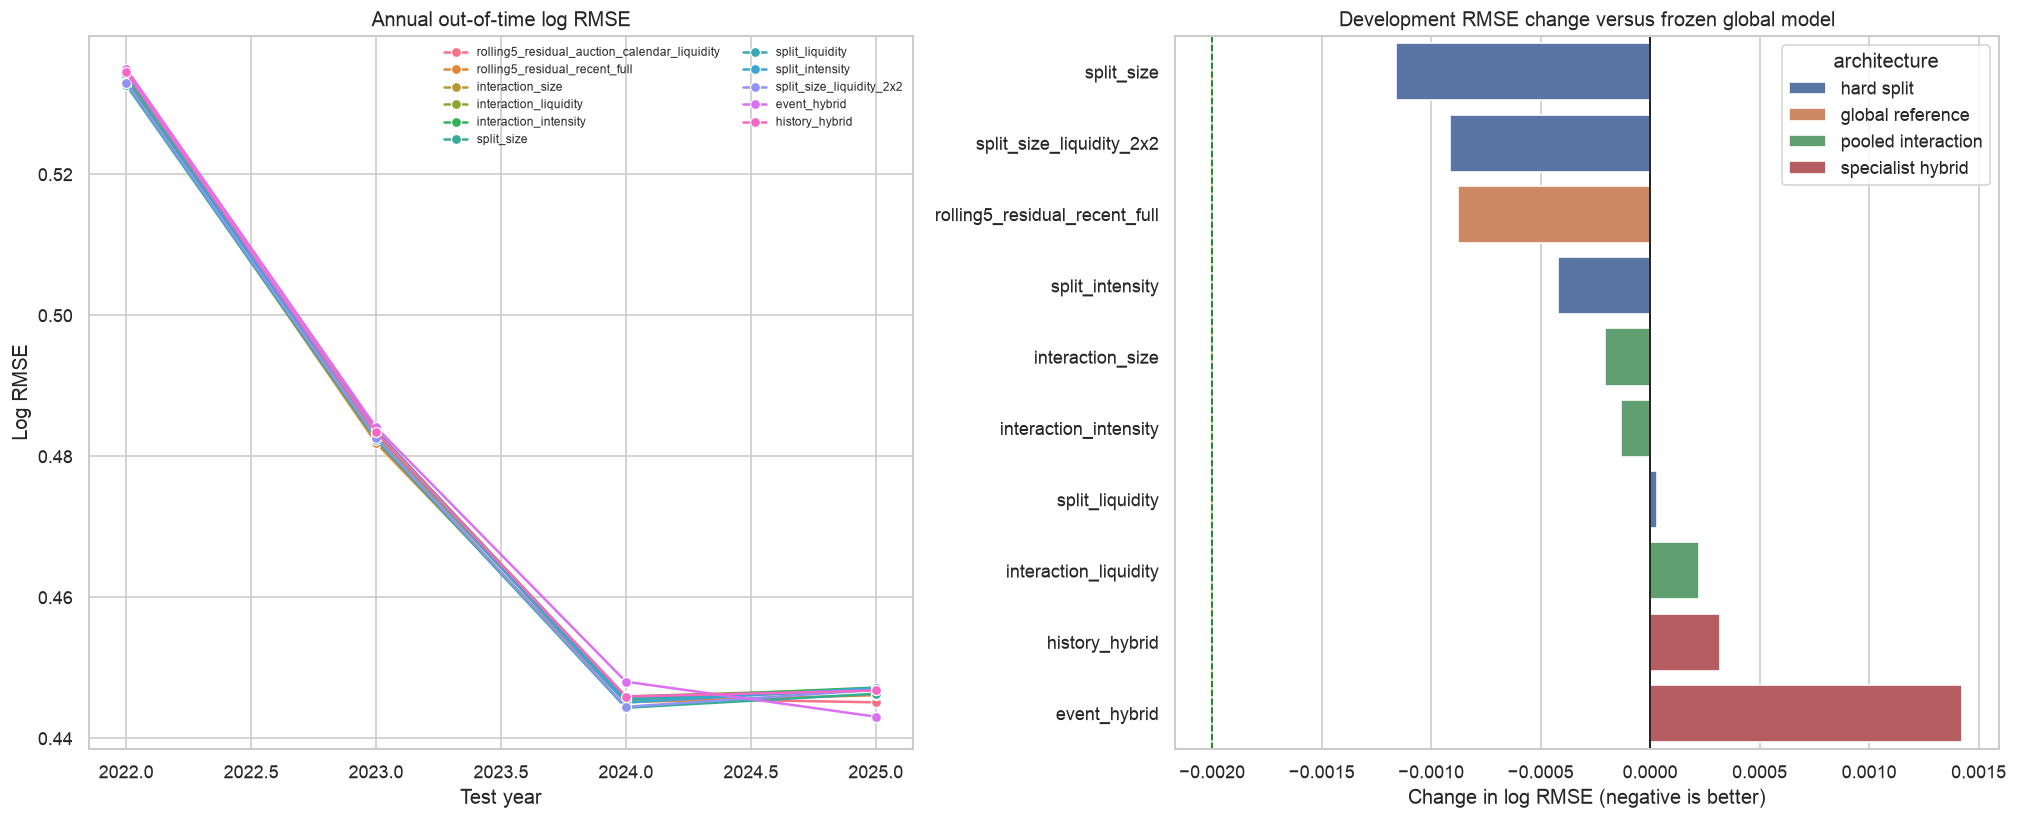

,candidate,architecture,development_rmse_log,development_wape,development_spearman,development_bias,worst_development_rmse,confirmation_rmse_log,confirmation_wape,confirmation_spearman,confirmation_bias,rmse_change_vs_frozen,rmse_change_vs_secondary,practical_rmse_improvement,beats_secondary_rmse,mean_difference,ci_2_5,ci_97_5,paired_log_mae_significant,stable_each_development_year,eligible_general_replacement
0,split_size,hard split,0.48648,0.36415,0.95494,-0.15180,0.53271,0.44634,0.34212,0.95889,-0.10798,-0.00116,-0.00028,False,True,-0.00029,-0.00071,0.00013,False,True,False
1,split_size_liquidity_2x2,hard split,0.48673,0.36433,0.95489,-0.15195,0.53302,0.44689,0.34314,0.95884,-0.10652,-0.00091,-0.00004,False,True,-0.00027,-0.00068,0.00013,False,True,False
2,rolling5_residual_recent_full,global reference,0.48677,0.36734,0.95490,-0.13981,0.53322,0.44614,0.34142,0.95929,-0.12607,-0.00088,0.00000,False,False,0.00004,-0.00073,0.00082,False,True,False
3,split_intensity,hard split,0.48722,0.36821,0.95490,-0.13973,0.53306,0.44717,0.34620,0.95878,-0.09666,-0.00042,0.00046,False,False,0.00030,-0.00006,0.00066,False,True,False
4,interaction_size,pooled interaction,0.48743,0.36591,0.95484,-0.15057,0.53390,0.44686,0.34367,0.95881,-0.10412,-0.00021,0.00067,False,False,-0.00015,-0.00042,0.00011,False,True,False
5,interaction_intensity,pooled interaction,0.48751,0.36809,0.95488,-0.14136,0.53323,0.44722,0.34582,0.95881,-0.09772,-0.00014,0.00074,False,False,0.00031,0.00000,0.00060,False,True,False
6,rolling5_residual_auction_calendar_liquidity,global reference,0.48764,0.36801,0.95487,-0.14378,0.53351,0.44512,0.34563,0.95880,-0.09623,0.00000,0.00088,False,False,NaN,NaN,NaN,False,True,False
7,split_liquidity,hard split,0.48767,0.36573,0.95486,-0.15160,0.53398,0.44699,0.34316,0.95881,-0.10550,0.00003,0.00091,False,False,0.00002,-0.00026,0.00032,False,True,False
8,interaction_liquidity,pooled interaction,0.48786,0.36608,0.95482,-0.15303,0.53401,0.44703,0.34375,0.95886,-0.10412,0.00022,0.00110,False,False,-0.00018,-0.00042,0.00007,False,True,False
9,history_hybrid,specialist hybrid,0.48796,0.36700,0.95484,-0.14758,0.53449,0.44681,0.34533,0.95890,-0.09674,0.00032,0.00120,False,False,0.00010,-0.00011,0.00032,False,True,False


{
  "frozen_global_benchmark": "rolling5_residual_auction_calendar_liquidity",
  "secondary_global_challenger": "rolling5_residual_recent_full",
  "eligible_general_replacements": [],
  "best_numeric_architecture": "split_size",
  "best_numeric_development_rmse": 0.48648038196476273,
  "retain_frozen_global_as_primary": true,
  "targeted_tests_with_significant_log_mae_improvement": []
}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.lineplot(data=metrics, x="test_year", y="rmse_log", hue="candidate", marker="o", ax=axes[0])
axes[0].set(title="Annual out-of-time log RMSE", xlabel="Test year", ylabel="Log RMSE")
axes[0].legend(fontsize=7, frameon=False, ncol=2)

plot_summary = summary[summary["candidate"] != CHAMPION].sort_values("rmse_change_vs_frozen")
sns.barplot(data=plot_summary, y="candidate", x="rmse_change_vs_frozen",
            hue="architecture", dodge=False, ax=axes[1])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].axvline(-0.002, color="green", linestyle="--", linewidth=1)
axes[1].set(title="Development RMSE change versus frozen global model",
            xlabel="Change in log RMSE (negative is better)", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "segmentation_architecture_comparison.png", bbox_inches="tight")
plt.show()

dev_boot = bootstrap[(bootstrap["reference"] == CHAMPION) &
                     (bootstrap["period"] == "development_2022_2024") &
                     (bootstrap["metric"] == "log_mae_difference")][
    ["candidate", "mean_difference", "ci_2_5", "ci_97_5"]
]
decision = summary.merge(dev_boot, on="candidate", how="left")
decision["paired_log_mae_significant"] = decision["ci_97_5"] < 0
decision["stable_each_development_year"] = decision["candidate"].map(
    metrics[metrics["test_year"].isin(DEVELOPMENT_YEARS)].pivot(index="candidate", columns="test_year", values="rmse_log")
        .sub(metrics[(metrics["candidate"] == CHAMPION) & metrics["test_year"].isin(DEVELOPMENT_YEARS)]
             .set_index("test_year")["rmse_log"], axis=1)
        .max(axis=1).le(0.002)
)
decision["eligible_general_replacement"] = (
    decision["practical_rmse_improvement"]
    & decision["beats_secondary_rmse"]
    & decision["paired_log_mae_significant"].fillna(False)
    & decision["stable_each_development_year"].fillna(False)
)
decision.to_csv(OUT / "segmentation_decision_table.csv", index=False)
display(decision.sort_values("development_rmse_log"))

eligible = decision.loc[decision["eligible_general_replacement"], "candidate"].tolist()
target_dev = target_bootstrap[target_bootstrap["period"] == "development_2022_2024"].copy()
target_dev["significant_improvement"] = target_dev["ci_97_5"] < 0
recommendation = {
    "frozen_global_benchmark": CHAMPION,
    "secondary_global_challenger": SECONDARY,
    "eligible_general_replacements": eligible,
    "best_numeric_architecture": summary.iloc[0]["candidate"],
    "best_numeric_development_rmse": float(summary.iloc[0]["development_rmse_log"]),
    "retain_frozen_global_as_primary": len(eligible) == 0,
    "targeted_tests_with_significant_log_mae_improvement": target_dev.loc[
        target_dev["significant_improvement"], ["candidate", "dimension", "segment"]
    ].to_dict("records"),
}
with open(OUT / "model_architecture_recommendation.json", "w") as handle:
    json.dump(recommendation, handle, indent=2)
print(json.dumps(recommendation, indent=2))

## Interpretation guardrails

- A general split is recommended only when it clears the practical RMSE threshold, paired uncertainty check, and annual stability check.
- A targeted hybrid may still be useful when its affected regime improves materially and ordinary observations are unchanged, even if the universe-wide RMSE barely moves.
- 2025 is confirmation evidence, not a pristine untouched holdout, because it was inspected in earlier notebooks.
- Failure of linear ridge splits does not prove that segmentation can never help; it means the tested linear separation is not justified by the current data.

In [10]:
artifacts = pd.DataFrame({
    "artifact": [
        "Candidate design", "Architecture summary", "Decision table", "Annual metrics",
        "Paired date bootstrap", "Segment metrics", "Targeted segment improvements",
        "Targeted segment bootstrap", "Training counts", "Lambda validation",
        "Architecture recommendation", "Comparison figure", "Predictions",
    ],
    "path": [
        OUT / "candidate_design.csv", OUT / "segmentation_architecture_summary.csv",
        OUT / "segmentation_decision_table.csv", OUT / "segmentation_candidate_metrics.csv",
        OUT / "segmentation_date_block_bootstrap.csv", OUT / "segmentation_segment_metrics.csv",
        OUT / "targeted_segment_improvements.csv", OUT / "targeted_segment_date_bootstrap.csv",
        OUT / "segment_training_counts.csv",
        OUT / "segmentation_lambda_validation.csv", OUT / "model_architecture_recommendation.json",
        OUT / "segmentation_architecture_comparison.png", PREDICTIONS,
    ],
})
artifacts["path"] = artifacts["path"].astype(str)
artifacts.to_csv(OUT / "artifact_manifest.csv", index=False)
display(artifacts)

,artifact,path
0,Candidate design,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,Architecture summary,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,Decision table,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
3,Annual metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
4,Paired date bootstrap,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
5,Segment metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
6,Targeted segment improvements,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
7,Targeted segment bootstrap,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
8,Training counts,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
9,Lambda validation,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
